In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentPerformanceFactors.csv")

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nExam Score Statistics:")
display(df["Exam_Score"].describe())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

In [3]:

missing_data = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data[
    missing_data["Missing_Count"] > 0
]

display(missing_data.round(2))


,Missing_Count,Missing_Percentage
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01


In [5]:

print("Exam Scores Above 100:")
display(df[df["Exam_Score"] > 100])

print("Number of Scores Above 100:")
print((df["Exam_Score"] > 100).sum())

print("Number of Scores Below 0:")
print((df["Exam_Score"] < 0).sum())


Exam Scores Above 100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


Number of Scores Above 100:
1
Number of Scores Below 0:
0


In [6]:

df_clean = df[
    df["Exam_Score"].between(0, 100)
].copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Invalid Records Removed:", len(df) - len(df_clean))

print("Minimum Exam Score:", df_clean["Exam_Score"].min())
print("Maximum Exam Score:", df_clean["Exam_Score"].max())


Original Dataset Shape: (6607, 20)
Cleaned Dataset Shape: (6606, 20)
Invalid Records Removed: 1
Minimum Exam Score: 55
Maximum Exam Score: 100


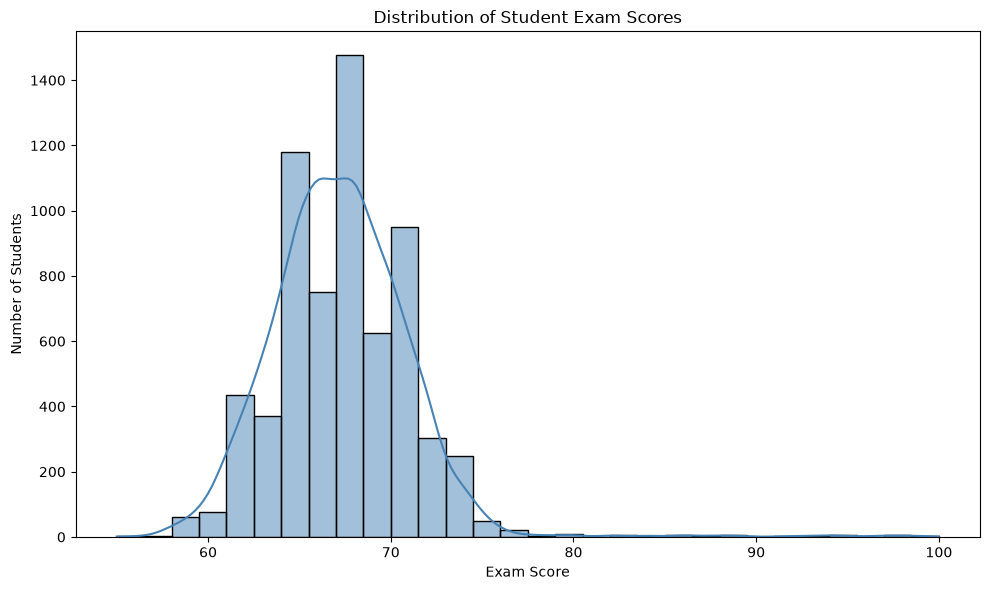

Distribution graph saved successfully!


In [7]:

import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Exam_Score",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.tight_layout()

plt.savefig(
    "outputs/exam_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Distribution graph saved successfully!")


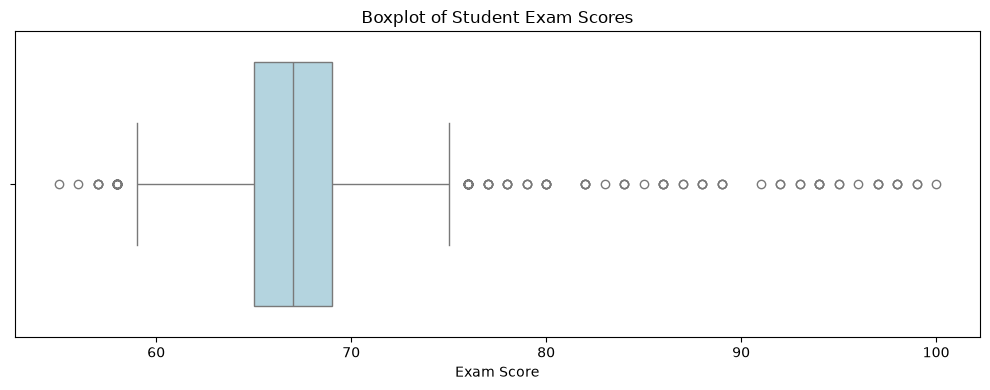

Boxplot saved successfully!


In [8]:

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df_clean["Exam_Score"],
    color="lightblue"
)

plt.title("Boxplot of Student Exam Scores")
plt.xlabel("Exam Score")

plt.tight_layout()

plt.savefig(
    "outputs/exam_score_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Boxplot saved successfully!")


In [9]:

from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Exam_Score"])
y = df_clean["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (5284, 19)
Testing Features: (1322, 19)
Training Target: (5284,)
Testing Target: (1322,)


In [10]:

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Count:", len(numerical_features))
print("Categorical Count:", len(categorical_features))


Numerical Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical Features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Numerical Count: 6
Categorical Count: 13


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!


In [12]:

import os

os.makedirs("data", exist_ok=True)

df_clean.to_csv(
    "data/student_performance_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Dataset Shape:", df_clean.shape)


Cleaned dataset saved successfully!
Dataset Shape: (6606, 20)


## 6. Linear Regression Model Training

In [13]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression Pipeline Created Successfully!")


Linear Regression Pipeline Created Successfully!


In [14]:

linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [15]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_train_pred = linear_model.predict(X_train)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

print("Linear Regression Training Results")
print("----------------------------------")
print(f"MAE: {train_mae:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R2 Score: {train_r2:.4f}")


Linear Regression Training Results
----------------------------------
MAE: 0.5030
RMSE: 2.1092
R2 Score: 0.7110


In [16]:

from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

linear_cv = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

linear_cv_results = {
    "Model": "Linear Regression",
    "MAE": -linear_cv["test_MAE"].mean(),
    "RMSE": -linear_cv["test_RMSE"].mean(),
    "R2": linear_cv["test_R2"].mean()
}

print("Linear Regression 5-Fold CV Results")
print("-----------------------------------")
print(f"MAE: {linear_cv_results['MAE']:.4f}")
print(f"RMSE: {linear_cv_results['RMSE']:.4f}")
print(f"R2 Score: {linear_cv_results['R2']:.4f}")


Linear Regression 5-Fold CV Results
-----------------------------------
MAE: 0.5111
RMSE: 2.0720
R2 Score: 0.7166


## 7. Random Forest Regressor

In [17]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Pipeline Created Successfully!")


Random Forest Pipeline Created Successfully!


In [18]:

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [19]:

rf_train_pred = rf_model.predict(X_train)

rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_pred)
)
rf_train_r2 = r2_score(y_train, rf_train_pred)

print("Random Forest Training Results")
print("--------------------------------")
print(f"MAE: {rf_train_mae:.4f}")
print(f"RMSE: {rf_train_rmse:.4f}")
print(f"R2 Score: {rf_train_r2:.4f}")


Random Forest Training Results
--------------------------------
MAE: 0.6213
RMSE: 1.4202
R2 Score: 0.8690


In [20]:

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = {
    "Model": "Random Forest",
    "MAE": -rf_cv["test_MAE"].mean(),
    "RMSE": -rf_cv["test_RMSE"].mean(),
    "R2": rf_cv["test_R2"].mean()
}

print("Random Forest 5-Fold CV Results")
print("--------------------------------")
print(f"MAE: {rf_cv_results['MAE']:.4f}")
print(f"RMSE: {rf_cv_results['RMSE']:.4f}")
print(f"R2 Score: {rf_cv_results['R2']:.4f}")


Random Forest 5-Fold CV Results
--------------------------------
MAE: 1.1713
RMSE: 2.3986
R2 Score: 0.6241


In [21]:

comparison_df = pd.DataFrame([
    linear_cv_results,
    rf_cv_results
])

display(comparison_df.round(4))

comparison_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


,Model,MAE,RMSE,R2
0,Linear Regression,0.5111,2.0720,0.7166
1,Random Forest,1.1713,2.3986,0.6241


Model comparison saved successfully!


In [22]:

%pip install xgboost


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 8. XGBoost Regressor

In [23]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

print("XGBoost Pipeline Created Successfully!")


XGBoost Pipeline Created Successfully!


In [24]:

xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")


XGBoost Model Trained Successfully!


In [25]:

xgb_train_pred = xgb_model.predict(X_train)

xgb_train_mae = mean_absolute_error(
    y_train, xgb_train_pred
)
xgb_train_rmse = np.sqrt(
    mean_squared_error(y_train, xgb_train_pred)
)
xgb_train_r2 = r2_score(
    y_train, xgb_train_pred
)

print("XGBoost Training Results")
print("------------------------")
print(f"MAE: {xgb_train_mae:.4f}")
print(f"RMSE: {xgb_train_rmse:.4f}")
print(f"R2 Score: {xgb_train_r2:.4f}")


XGBoost Training Results
------------------------
MAE: 0.7345
RMSE: 2.0317
R2 Score: 0.7318


In [26]:

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

xgb_cv_results = {
    "Model": "XGBoost",
    "MAE": -xgb_cv["test_MAE"].mean(),
    "RMSE": -xgb_cv["test_RMSE"].mean(),
    "R2": xgb_cv["test_R2"].mean()
}

print("XGBoost 5-Fold CV Results")
print("-------------------------")
print(f"MAE: {xgb_cv_results['MAE']:.4f}")
print(f"RMSE: {xgb_cv_results['RMSE']:.4f}")
print(f"R2 Score: {xgb_cv_results['R2']:.4f}")


XGBoost 5-Fold CV Results
-------------------------
MAE: 0.8138
RMSE: 2.1885
R2 Score: 0.6853


In [27]:

comparison_df = pd.DataFrame([
    linear_cv_results,
    rf_cv_results,
    xgb_cv_results
])

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(comparison_df.round(4))

comparison_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("All three models compared successfully!")


,Model,MAE,RMSE,R2
0,Linear Regression,0.5111,2.0720,0.7166
1,XGBoost,0.8138,2.1885,0.6853
2,Random Forest,1.1713,2.3986,0.6241


All three models compared successfully!


## 9. Best Model Selection and Final Evaluation

In [28]:

best_model_name = comparison_df.iloc[0]["Model"]

models = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = models[best_model_name]

print("Selected Best Model:", best_model_name)


Selected Best Model: Linear Regression


In [29]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_test_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Final Test Evaluation Results")
print("-----------------------------")
print(f"Model: {best_model_name}")
print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2 Score: {test_r2:.4f}")


Final Test Evaluation Results
-----------------------------
Model: Linear Regression
MAE: 0.4160
RMSE: 1.5213
R2 Score: 0.8250


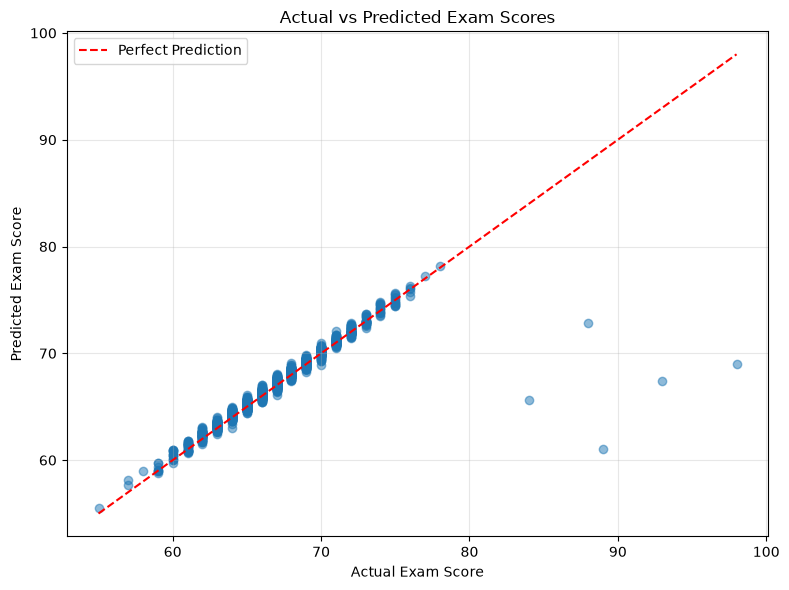

Actual vs Predicted graph saved!


In [30]:

import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.5
)

min_score = min(y_test.min(), y_test_pred.min())
max_score = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/actual_vs_predicted.png",
    dpi=300
)

plt.show()

print("Actual vs Predicted graph saved!")


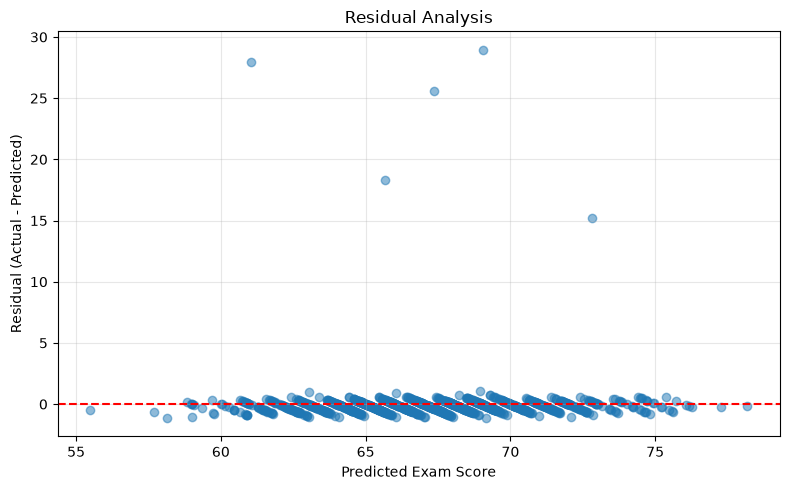

Residual analysis graph saved!


In [31]:

residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/residual_analysis.png",
    dpi=300
)

plt.show()

print("Residual analysis graph saved!")


## 10. Save the Best Trained Model

In [32]:

import joblib
import os

os.makedirs("models", exist_ok=True)

model_path = "models/best_model.pkl"

joblib.dump(best_model, model_path)

print("Best Model Saved Successfully!")
print("Model:", best_model_name)
print("Saved Path:", model_path)


Best Model Saved Successfully!
Model: Linear Regression
Saved Path: models/best_model.pkl


In [33]:

loaded_model = joblib.load("models/best_model.pkl")

sample_input = X_test.iloc[[0]]
original_prediction = best_model.predict(sample_input)[0]
loaded_prediction = loaded_model.predict(sample_input)[0]

print("Original Prediction:", round(original_prediction, 4))
print("Loaded Model Prediction:", round(loaded_prediction, 4))
print(
    "Model Verification:",
    np.isclose(original_prediction, loaded_prediction)
)


Original Prediction: 66.0146
Loaded Model Prediction: 66.0146
Model Verification: True


## 11. Baseline Model Evaluation

In [34]:

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

dummy_model = DummyRegressor(strategy="mean")

dummy_cv = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

dummy_cv_results = {
    "Model": "Dummy Baseline",
    "MAE": -dummy_cv["test_MAE"].mean(),
    "RMSE": -dummy_cv["test_RMSE"].mean(),
    "R2": dummy_cv["test_R2"].mean()
}

print("Dummy Baseline 5-Fold CV Results")
print("--------------------------------")
print(f"MAE: {dummy_cv_results['MAE']:.4f}")
print(f"RMSE: {dummy_cv_results['RMSE']:.4f}")
print(f"R2 Score: {dummy_cv_results['R2']:.4f}")


Dummy Baseline 5-Fold CV Results
--------------------------------
MAE: 2.8683
RMSE: 3.9202
R2 Score: -0.0028


In [35]:

comparison_df = pd.DataFrame([
    dummy_cv_results,
    linear_cv_results,
    rf_cv_results,
    xgb_cv_results
])

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(comparison_df.round(4))

comparison_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Four-model comparison saved successfully!")


,Model,MAE,RMSE,R2
0,Linear Regression,0.5111,2.0720,0.7166
1,XGBoost,0.8138,2.1885,0.6853
2,Random Forest,1.1713,2.3986,0.6241
3,Dummy Baseline,2.8683,3.9202,-0.0028


Four-model comparison saved successfully!


## 12. Hyperparameter Tuning

In [36]:

from sklearn.model_selection import RandomizedSearchCV, KFold

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_param_grid = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [5, 10, 15, None],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.5, 0.8, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Random Forest Tuning Completed!")
print("Best Parameters:", rf_search.best_params_)
print("Best CV RMSE:", round(-rf_search.best_score_, 4))


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest Tuning Completed!
Best Parameters: {'regressor__n_estimators': 300, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 4, 'regressor__max_features': 0.5, 'regressor__max_depth': None}
Best CV RMSE: 2.3486


In [37]:

tuned_rf = rf_search.best_estimator_

tuned_rf_cv = cross_validate(
    tuned_rf,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=-1
)

tuned_rf_results = {
    "Model": "Tuned Random Forest",
    "MAE": -tuned_rf_cv["test_MAE"].mean(),
    "RMSE": -tuned_rf_cv["test_RMSE"].mean(),
    "R2": tuned_rf_cv["test_R2"].mean()
}

print("Tuned Random Forest CV Results")
print("------------------------------")
print(f"MAE: {tuned_rf_results['MAE']:.4f}")
print(f"RMSE: {tuned_rf_results['RMSE']:.4f}")
print(f"R2 Score: {tuned_rf_results['R2']:.4f}")


Tuned Random Forest CV Results
------------------------------
MAE: 1.1058
RMSE: 2.3486
R2 Score: 0.6414


## 13. XGBoost Hyperparameter Tuning

In [38]:

from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    "regressor__n_estimators": [100, 200, 300, 400],
    "regressor__max_depth": [2, 3, 4, 5],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__subsample": [0.7, 0.8, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 1.0],
    "regressor__reg_lambda": [1, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("XGBoost Tuning Completed!")
print("Best Parameters:", xgb_search.best_params_)
print("Best CV RMSE:", round(-xgb_search.best_score_, 4))


Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost Tuning Completed!
Best Parameters: {'regressor__subsample': 0.8, 'regressor__reg_lambda': 5, 'regressor__n_estimators': 400, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.05, 'regressor__colsample_bytree': 0.8}
Best CV RMSE: 2.166


In [39]:

tuned_xgb = xgb_search.best_estimator_

xgb_tuned_results = {
    "Model": "Tuned XGBoost",
    "Best CV RMSE": -xgb_search.best_score_,
    "Best Parameters": xgb_search.best_params_
}

print("Tuned XGBoost Results")
print("---------------------")
print("Best CV RMSE:",
      round(xgb_tuned_results["Best CV RMSE"], 4))
print("Best Parameters:",
      xgb_tuned_results["Best Parameters"])


Tuned XGBoost Results
---------------------
Best CV RMSE: 2.166
Best Parameters: {'regressor__subsample': 0.8, 'regressor__reg_lambda': 5, 'regressor__n_estimators': 400, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.05, 'regressor__colsample_bytree': 0.8}


## 14. Feature Importance Analysis

In [40]:

import pandas as pd
import numpy as np

trained_preprocessor = linear_model.named_steps["preprocessor"]
trained_regressor = linear_model.named_steps["regressor"]

feature_names = trained_preprocessor.get_feature_names_out()
coefficients = trained_regressor.coef_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

feature_importance_df = feature_importance_df.sort_values(
    by="Absolute_Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15).round(4))

print("Feature coefficients extracted successfully!")


,Feature,Coefficient,Absolute_Importance
0,num__Attendance,2.2845,2.2845
1,num__Hours_Studied,1.7439,1.7439
2,cat__Access_to_Resources_Low,-1.0503,1.0503
3,cat__Access_to_Resources_High,1.0441,1.0441
4,cat__Parental_Involvement_High,1.0342,1.0342
5,cat__Parental_Involvement_Low,-0.9854,0.9854
6,num__Previous_Scores,0.7033,0.7033
7,num__Tutoring_Sessions,0.5945,0.5945
8,cat__Motivation_Level_High,0.5467,0.5467
9,cat__Motivation_Level_Low,-0.5335,0.5335


Feature coefficients extracted successfully!


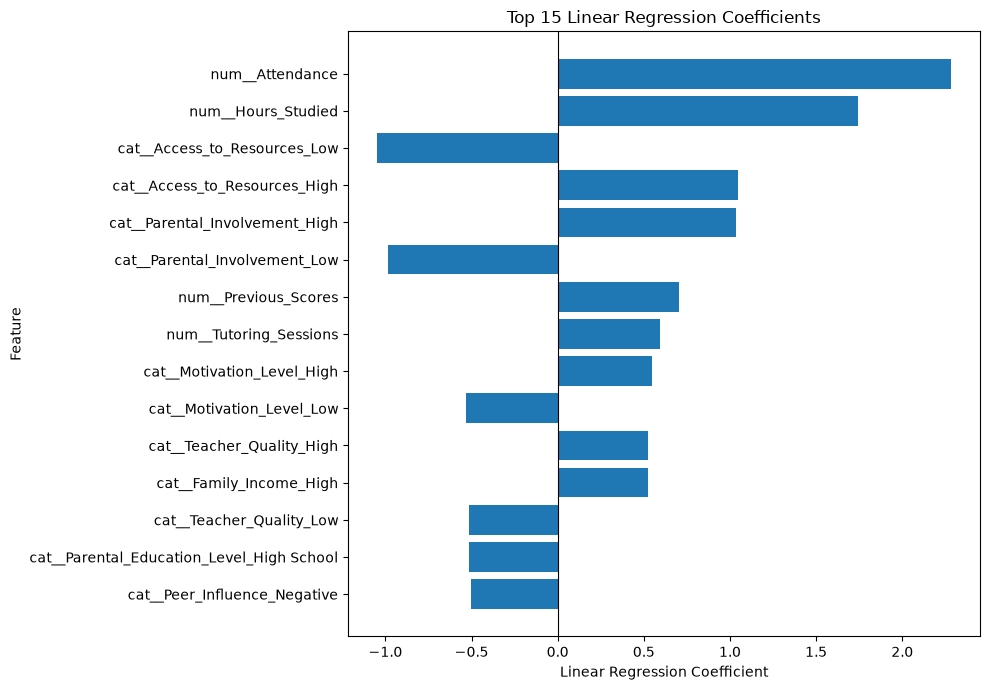

Feature importance graph saved successfully!


In [41]:

import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    by="Absolute_Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Linear Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Linear Regression Coefficients")

plt.tight_layout()

plt.savefig(
    "outputs/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance graph saved successfully!")


In [42]:

feature_importance_df.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

print("Feature importance table saved successfully!")


Feature importance table saved successfully!


## 15. Permutation Feature Importance

In [43]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

permutation_model = clone(linear_model)
permutation_model.fit(X_fit, y_fit)

print("Training Samples:", len(X_fit))
print("Validation Samples:", len(X_val))
print("Validation Model Trained Successfully!")


Training Samples: 4227
Validation Samples: 1057
Validation Model Trained Successfully!


In [44]:

from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    permutation_model,
    X_val,
    y_val,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_STD": permutation_results.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_df.round(4))

print("Permutation Importance Calculated Successfully!")


,Feature,Importance_Mean,Importance_STD
0,Attendance,1.8884,0.0332
1,Hours_Studied,1.2001,0.0342
2,Parental_Involvement,0.2556,0.0178
3,Access_to_Resources,0.2415,0.0190
4,Previous_Scores,0.2282,0.0209
5,Tutoring_Sessions,0.1853,0.0148
6,Peer_Influence,0.0783,0.0126
7,Parental_Education_Level,0.0736,0.0128
8,Motivation_Level,0.0735,0.0180
9,Teacher_Quality,0.0680,0.0062


Permutation Importance Calculated Successfully!


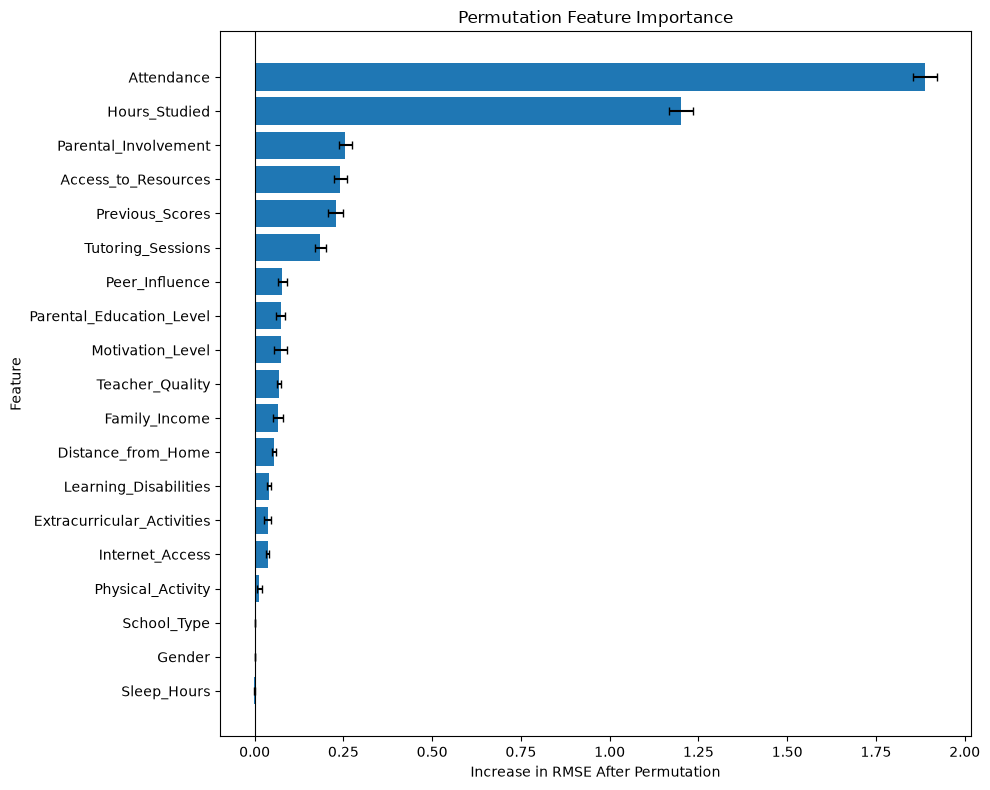

Permutation importance graph and CSV saved!


In [45]:

import matplotlib.pyplot as plt

plot_df = permutation_df.sort_values(
    by="Importance_Mean"
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_STD"],
    capsize=3
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Increase in RMSE After Permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")
plt.tight_layout()

plt.savefig(
    "outputs/permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

permutation_df.to_csv(
    "outputs/permutation_importance.csv",
    index=False
)

print("Permutation importance graph and CSV saved!")


## 16. Detailed Error Analysis

In [46]:

val_predictions = permutation_model.predict(X_val)

error_df = pd.DataFrame({
    "Actual_Score": y_val.to_numpy(),
    "Predicted_Score": val_predictions
})

error_df["Residual"] = (
    error_df["Actual_Score"] - error_df["Predicted_Score"]
)

error_df["Absolute_Error"] = error_df["Residual"].abs()

print("Validation Error Statistics")
print("---------------------------")
print(error_df["Absolute_Error"].describe().round(4))

print("\nTop 10 Largest Prediction Errors")
display(
    error_df.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10).round(4)
)


Validation Error Statistics
---------------------------
count    1057.0000
mean        0.4898
std         1.8171
min         0.0005
25%         0.1463
50%         0.3003
75%         0.4992
max        30.0199
Name: Absolute_Error, dtype: float64

Top 10 Largest Prediction Errors


,Actual_Score,Predicted_Score,Residual,Absolute_Error
632,97,66.9801,30.0199,30.0199
1023,95,68.9244,26.0756,26.0756
324,88,68.0321,19.9679,19.9679
1049,84,65.1222,18.8778,18.8778
941,82,63.2776,18.7224,18.7224
260,80,61.9187,18.0813,18.0813
63,89,71.7956,17.2044,17.2044
388,80,64.0726,15.9274,15.9274
422,68,66.6796,1.3204,1.3204
869,66,67.0718,-1.0718,1.0718


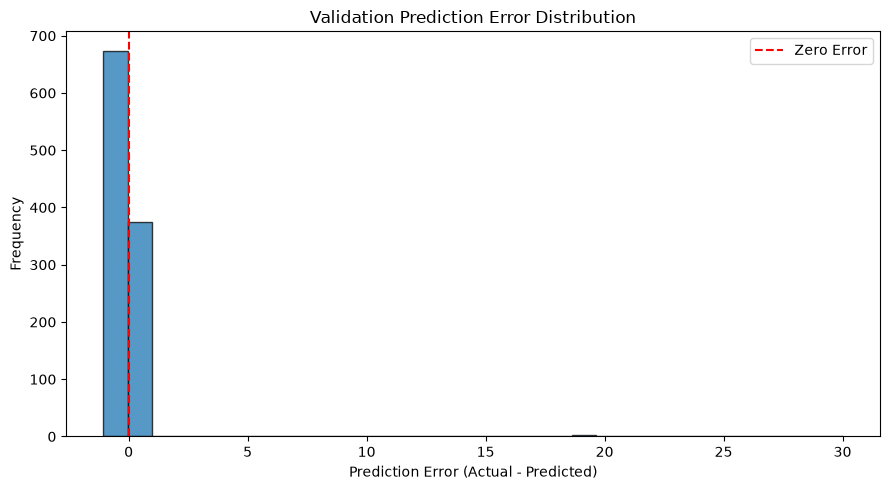

Error distribution graph saved successfully!


In [47]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    error_df["Residual"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Validation Prediction Error Distribution")
plt.legend()
plt.tight_layout()

plt.savefig(
    "outputs/error_distribution.png",
    dpi=300
)

plt.show()

print("Error distribution graph saved successfully!")


In [48]:

error_df["Score_Group"] = pd.cut(
    error_df["Actual_Score"],
    bins=[0, 60, 70, 80, 100],
    labels=[
        "0-60",
        "61-70",
        "71-80",
        "81-100"
    ],
    include_lowest=True
)

group_error_df = error_df.groupby(
    "Score_Group",
    observed=False
).agg(
    Student_Count=("Actual_Score", "count"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Maximum_Error=("Absolute_Error", "max")
).reset_index()

display(group_error_df.round(4))

group_error_df.to_csv(
    "outputs/error_by_score_group.csv",
    index=False
)

error_df.to_csv(
    "outputs/validation_error_analysis.csv",
    index=False
)

print("Detailed error analysis saved successfully!")


,Score_Group,Student_Count,Mean_Absolute_Error,Maximum_Error
0,0-60,26,0.4465,1.0703
1,61-70,862,0.3398,1.3204
2,71-80,163,0.5047,18.0813
3,81-100,6,21.8113,30.0199


Detailed error analysis saved successfully!


## 17. Final Model Comparison

In [49]:

from sklearn.model_selection import cross_validate, KFold
import pandas as pd

final_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

candidate_models = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Tuned Random Forest": tuned_rf,
    "Tuned XGBoost": tuned_xgb
}

final_results = []

for name, model in candidate_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=final_cv,
        scoring=scoring,
        n_jobs=-1
    )

    final_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

final_comparison_df = pd.DataFrame(final_results)

final_comparison_df = final_comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(final_comparison_df.round(4))

print("Consistent CV Comparison Completed!")


,Model,MAE,RMSE,R2
0,Linear Regression,0.5116,2.0840,0.7166
1,Tuned XGBoost,0.6890,2.1660,0.6943
2,XGBoost,0.8095,2.2038,0.6837
3,Tuned Random Forest,1.1058,2.3486,0.6414
4,Random Forest,1.1701,2.3980,0.6262


Consistent CV Comparison Completed!


In [50]:

final_comparison_df.to_csv(
    "outputs/final_model_comparison.csv",
    index=False
)

print("Final comparison table saved successfully!")


Final comparison table saved successfully!


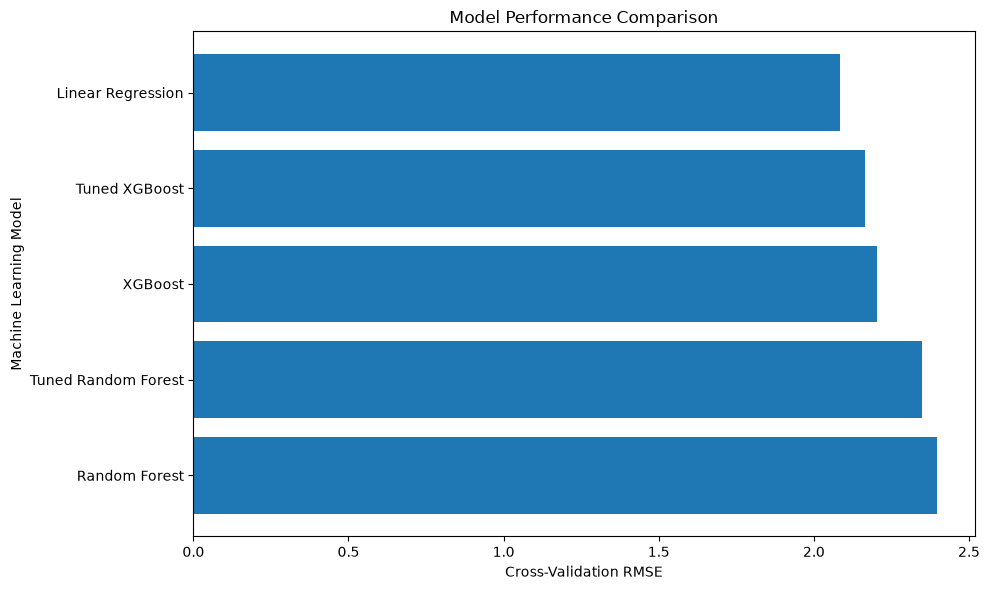

Model comparison graph saved!


In [51]:

import matplotlib.pyplot as plt

plot_df = final_comparison_df.sort_values(
    by="RMSE",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Model"],
    plot_df["RMSE"]
)

plt.xlabel("Cross-Validation RMSE")
plt.ylabel("Machine Learning Model")
plt.title("Model Performance Comparison")

plt.tight_layout()

plt.savefig(
    "outputs/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison graph saved!")


## 18. Final Model Verification

In [52]:

import joblib
import numpy as np

deployment_model = joblib.load("models/best_model.pkl")

print("Model Type:", type(
    deployment_model.named_steps["regressor"]
).__name__)

print("Expected Input Features:",
      deployment_model.feature_names_in_.shape[0])

print("Model Verification:",
      np.allclose(
          deployment_model.predict(X_test.iloc[:5]),
          linear_model.predict(X_test.iloc[:5])
      ))

print("Deployment Model Ready!")


Model Type: LinearRegression
Expected Input Features: 19
Model Verification: True
Deployment Model Ready!
